# Image Processing Fundamentals with OpenCV and Matplotlib
---
This notebook demonstrates basic image processing techniques and feature extraction using OpenCV, Matplotlib, and scikit-image.

In [37]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import hog
from skimage import exposure
from google.colab.patches import cv2_imshow

## 1. Read and Display Image

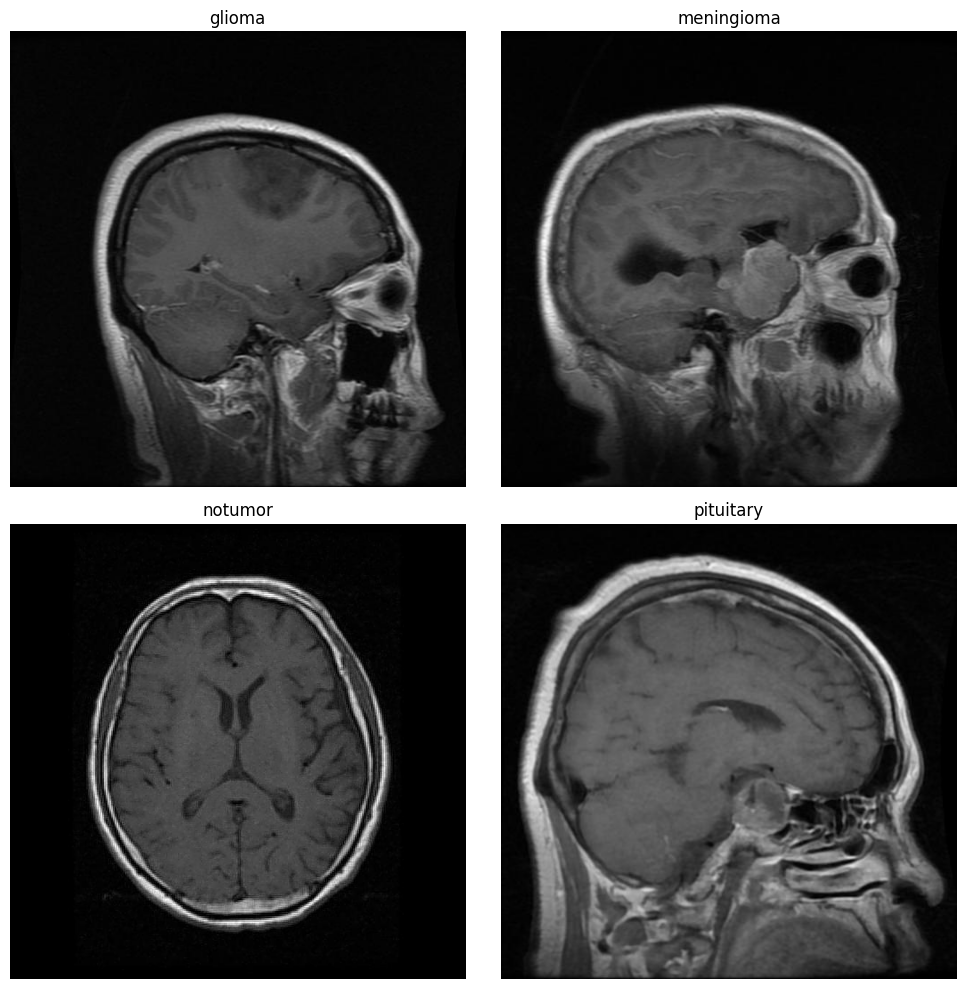

In [42]:
# Path ke 4 gambar
paths = [
    '/content/glioma.jpg',
    '/content/meningioma.jpg',
    '/content/notumor.jpg',
    '/content/pituitary.jpg'
]

# Load semua gambar dan konversi ke RGB
images = [cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB) for p in paths]
titles = ['glioma', 'meningioma', 'notumor', 'pituitary']

# Tampilkan dalam grid 2x2
plt.figure(figsize=(10, 10))

for i, (img, title) in enumerate(zip(images, titles), 1):
    plt.subplot(2, 2, i)
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()



## 2. Convert to Grayscale

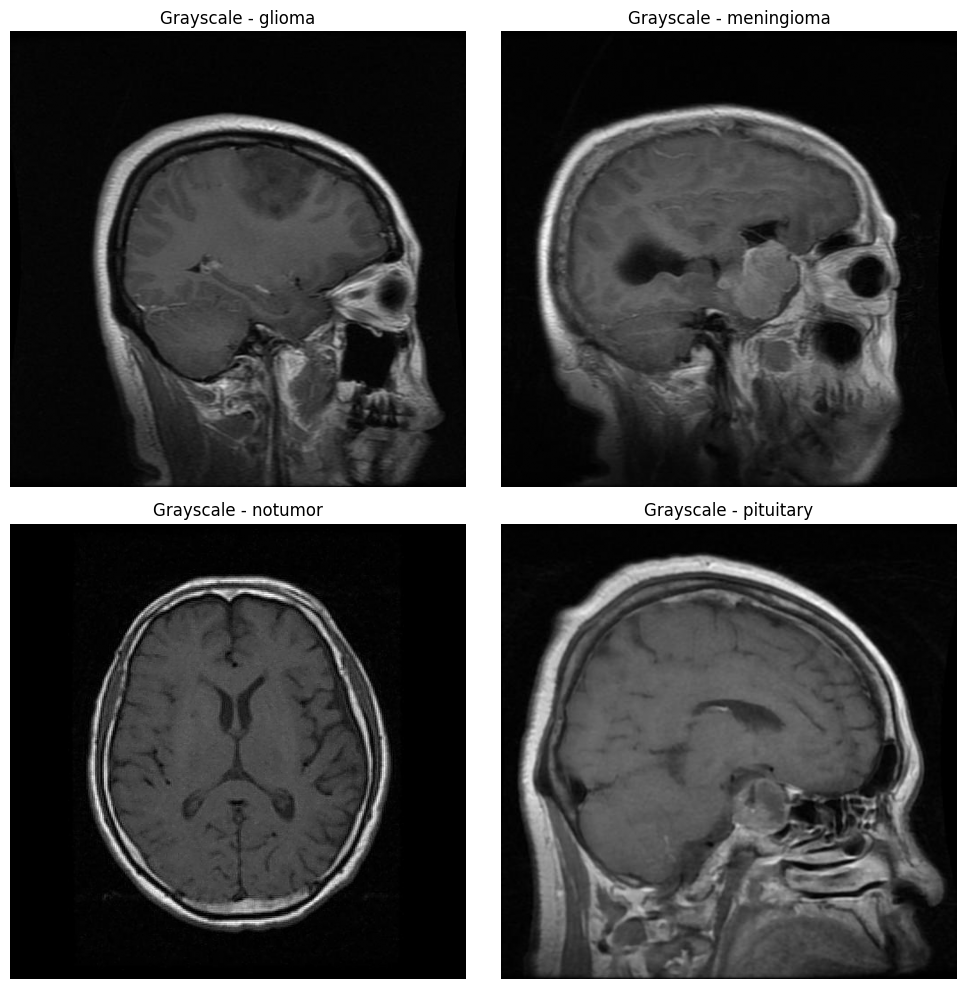

In [51]:

# Load semua gambar dan konversi ke grayscale
gray_images = [cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2GRAY) for p in paths]

# Tampilkan dalam grid 2x2
plt.figure(figsize=(10, 10))

for i, (gray, title) in enumerate(zip(gray_images, titles), 1):
    plt.subplot(2, 2, i)
    plt.imshow(gray, cmap='gray')
    plt.title(f"Grayscale - {title}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 3. Resize and Crop

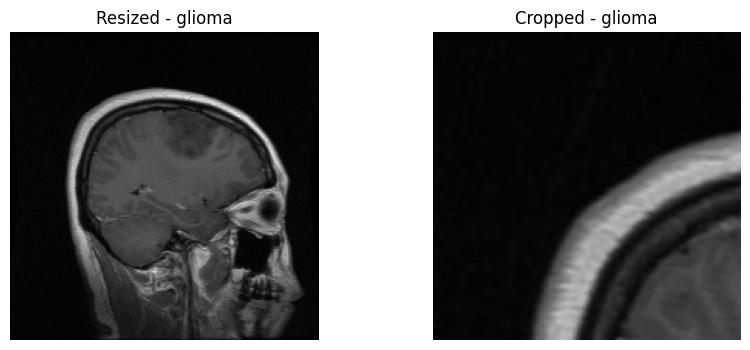

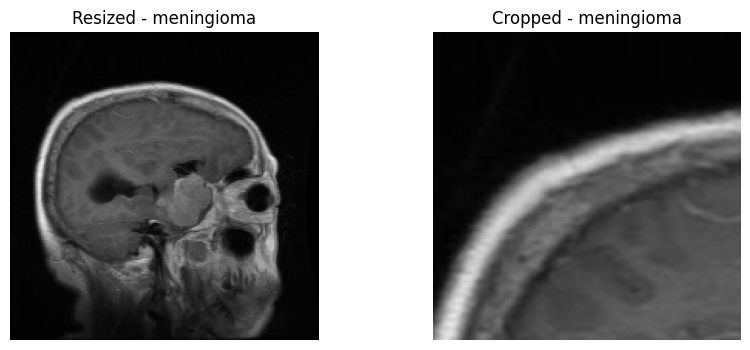

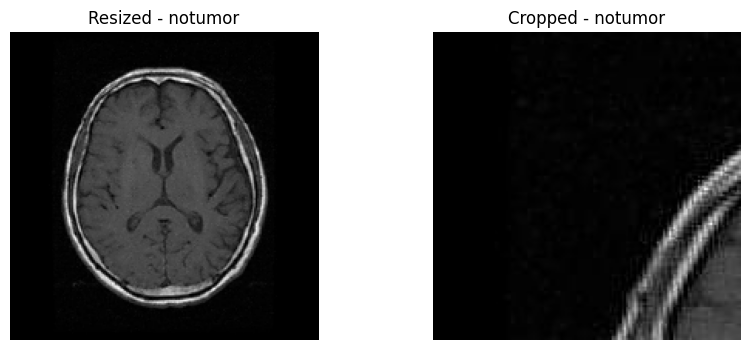

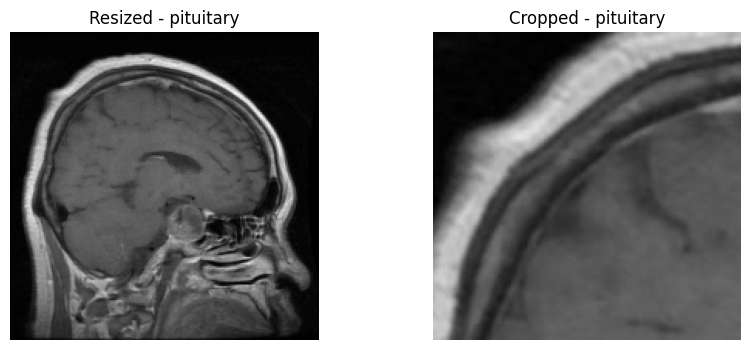

In [58]:
for path, title in zip(paths, titles):
    img = cv2.imread(path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    resized = cv2.resize(img_rgb, (200, 200))
    cropped = img_rgb[50:200, 50:200]

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(resized)
    plt.title(f"Resized - {title}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(cropped)
    plt.title(f"Cropped - {title}")
    plt.axis("off")

    plt.show()



## 4. Thresholding

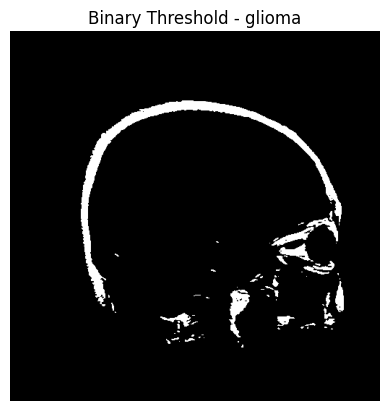

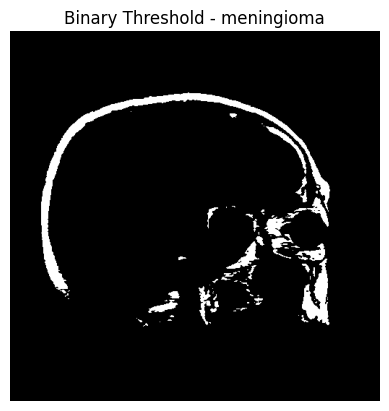

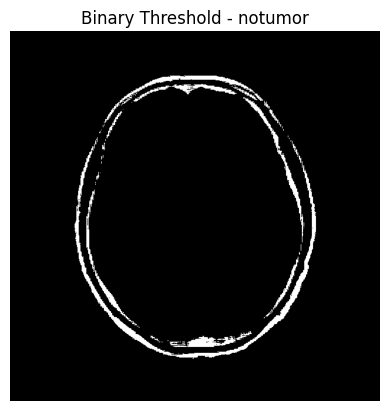

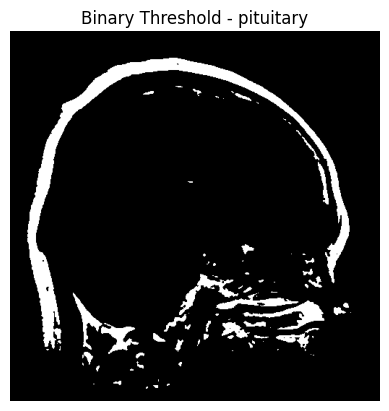

In [59]:

for path, title in zip(paths, titles):
    img = cv2.imread(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Thresholding biner
    _, binary = cv2.threshold(gray, 128, 255, cv2.THRESH_BINARY)

    plt.imshow(binary, cmap='gray')
    plt.title(f"Binary Threshold - {title}")
    plt.axis("off")
    plt.show()


## 5. Blurring and Smoothing

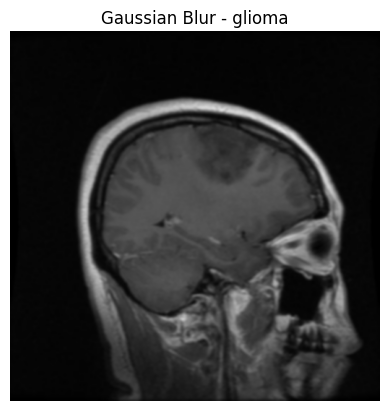

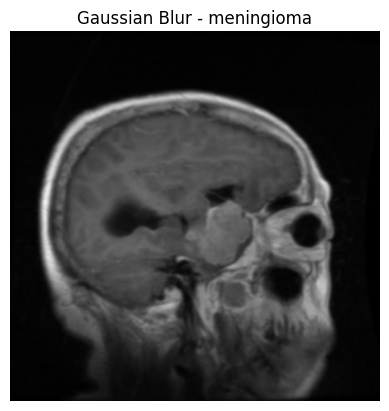

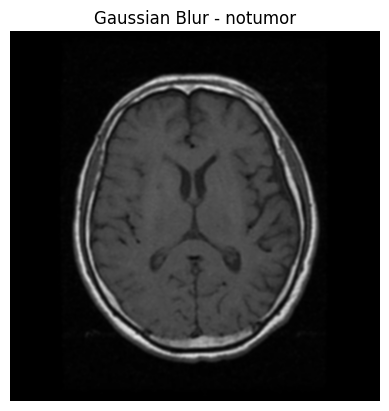

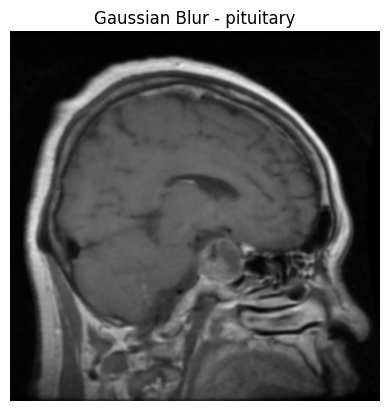

In [60]:

for path, title in zip(paths, titles):
    img = cv2.imread(path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Gaussian Blur
    blurred = cv2.GaussianBlur(img_rgb, (7, 7), 0)

    plt.imshow(blurred)
    plt.title(f"Gaussian Blur - {title}")
    plt.axis("off")
    plt.show()



## 6. Edge Detection (Canny)

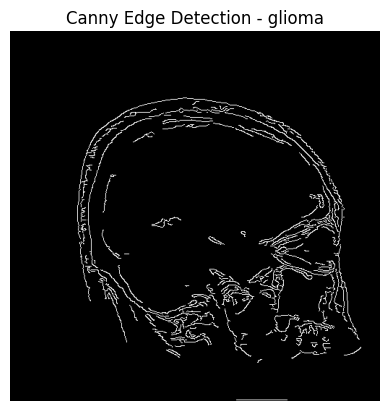

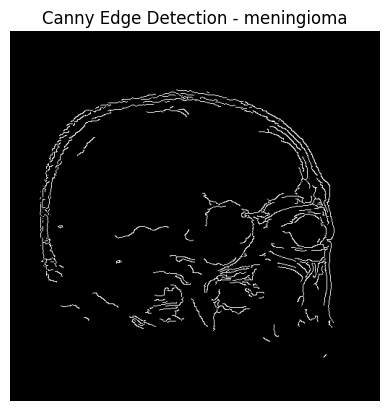

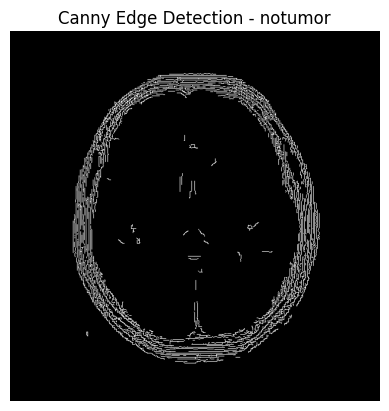

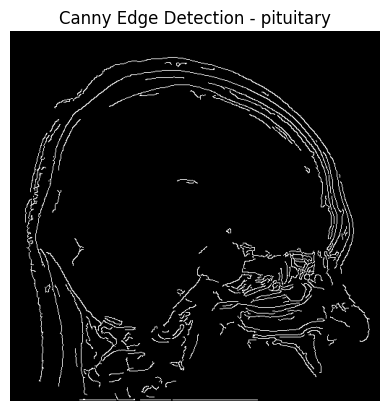

In [61]:

for path, title in zip(paths, titles):
    img = cv2.imread(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Canny Edge Detection
    edges = cv2.Canny(gray, 100, 200)

    plt.imshow(edges, cmap='gray')
    plt.title(f"Canny Edge Detection - {title}")
    plt.axis("off")
    plt.show()



## 7. Morphological Operations

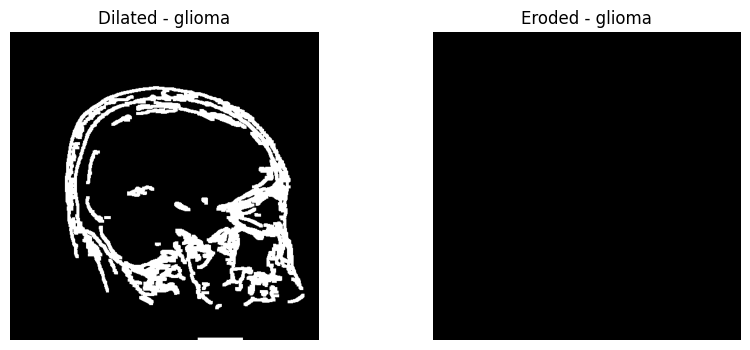

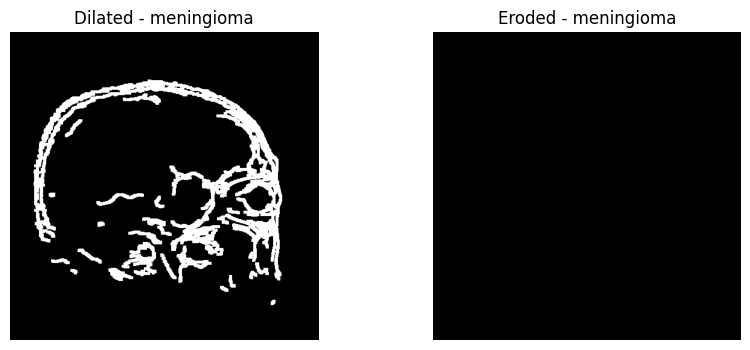

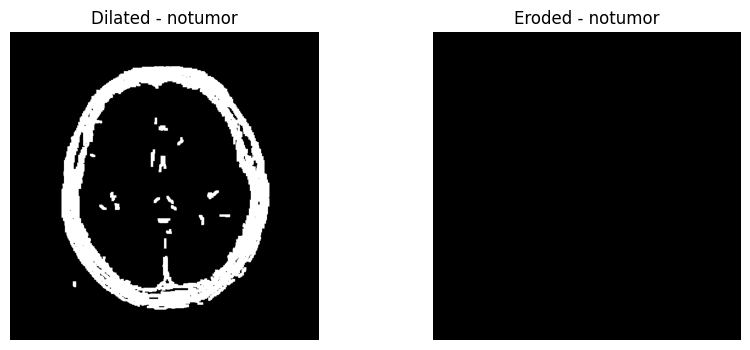

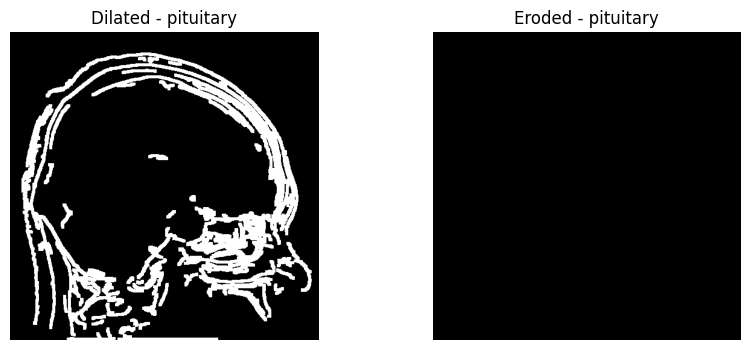

In [62]:

kernel = np.ones((5,5), np.uint8)

for path, title in zip(paths, titles):
    img = cv2.imread(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, 100, 200)  # gunakan hasil edge detection sebelumnya

    # Morphological Operations
    dilated = cv2.dilate(edges, kernel, iterations=1)
    eroded  = cv2.erode(edges, kernel, iterations=1)

    plt.figure(figsize=(10,4))
    plt.subplot(1,2,1)
    plt.imshow(dilated, cmap='gray')
    plt.title(f"Dilated - {title}")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(eroded, cmap='gray')
    plt.title(f"Eroded - {title}")
    plt.axis("off")
    plt.show()


## 8. Histogram of Grayscale Image

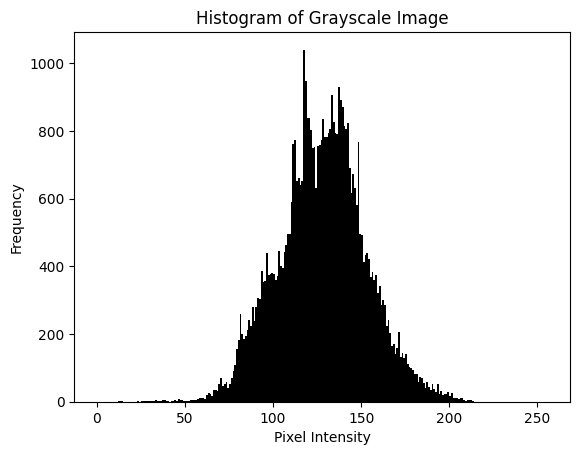

In [31]:

plt.hist(gray.ravel(), bins=256, range=(0,256), color='black')
plt.title("Histogram of Grayscale Image")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.show()


Histogram Equalization

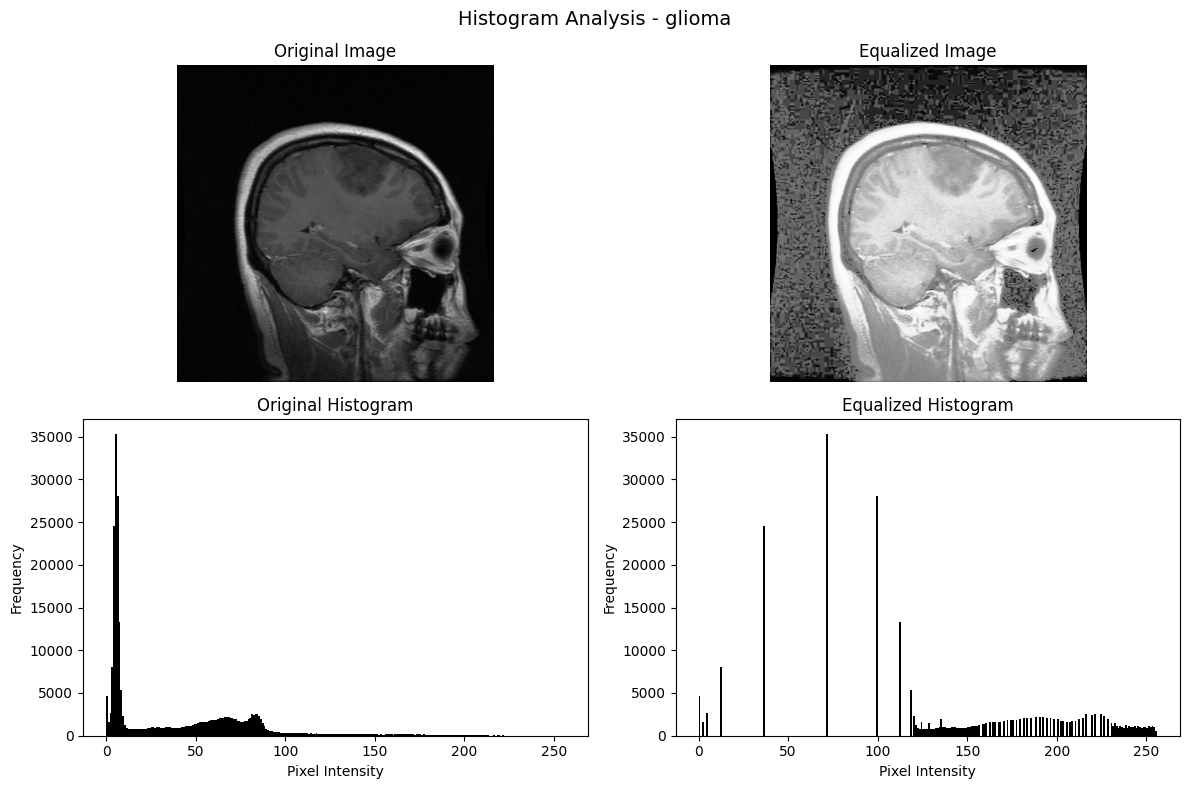

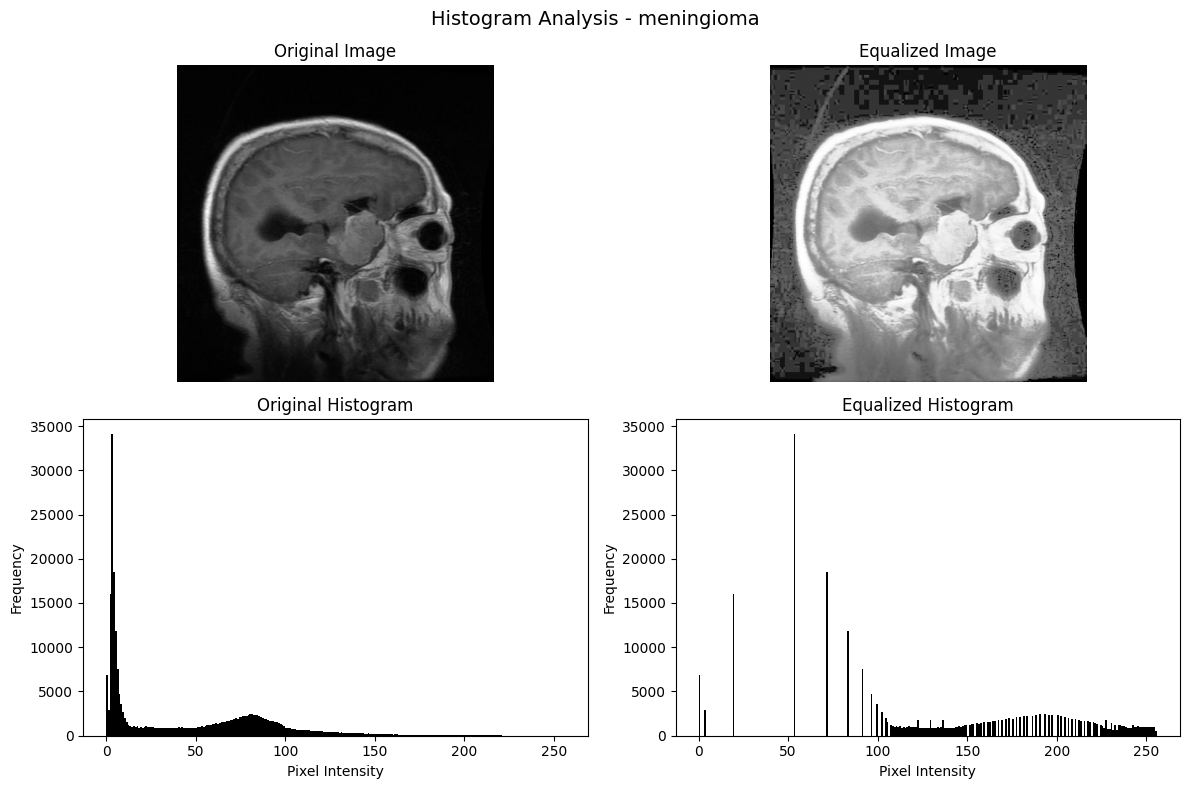

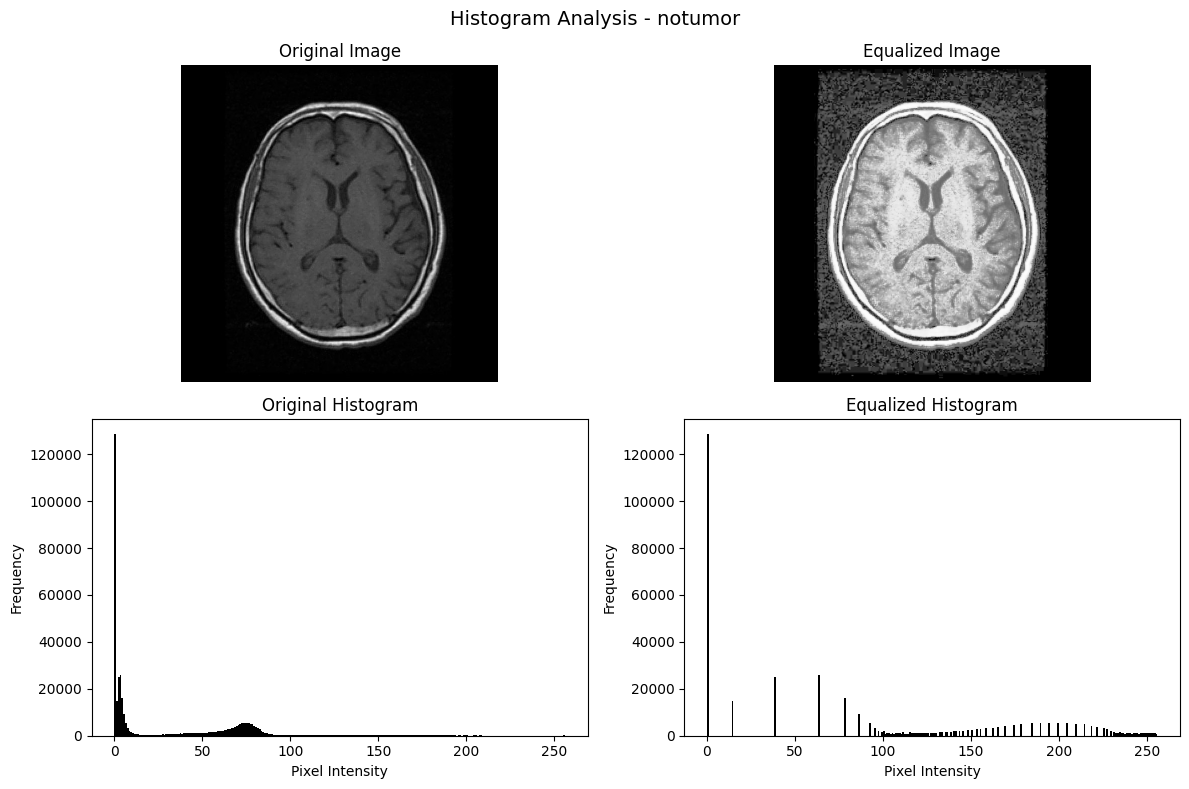

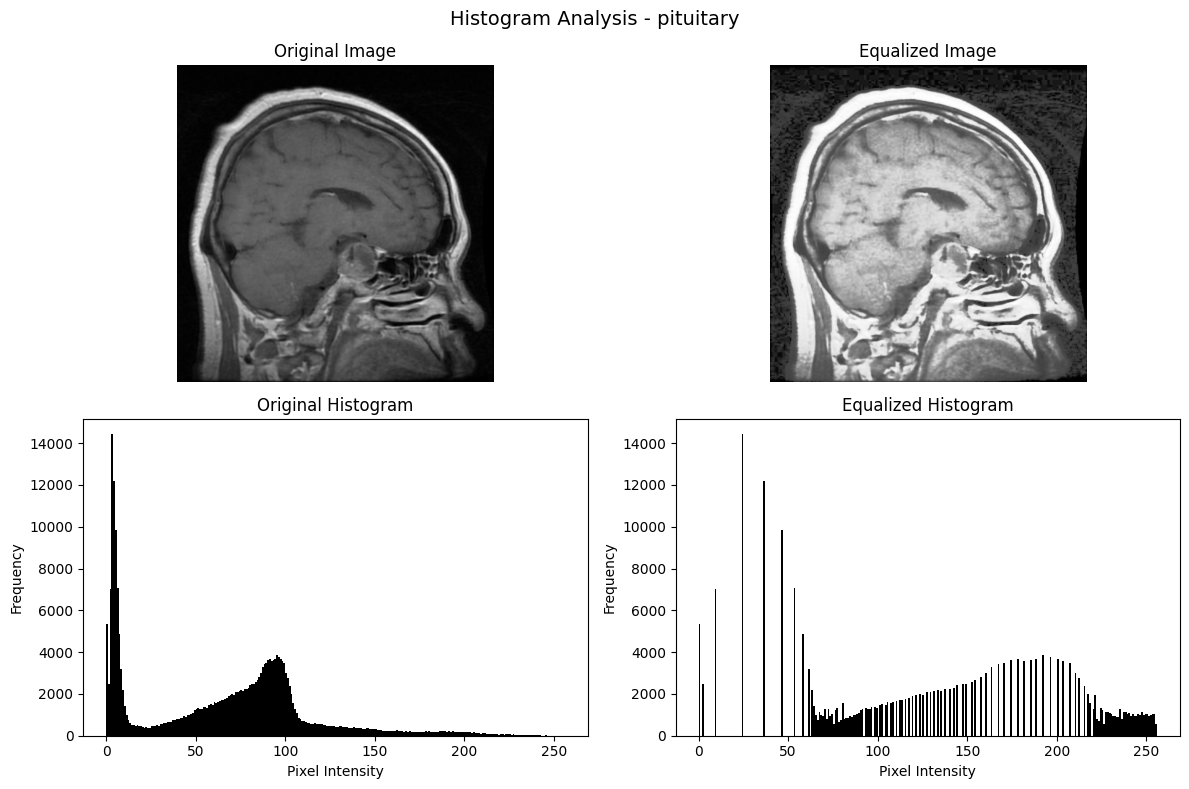

In [67]:
for path, title in zip(paths, titles):
    # Baca gambar dan konversi ke grayscale
    img = cv2.imread(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Histogram Equalization
    equalized = cv2.equalizeHist(gray)

    # Layout 2x2
    plt.figure(figsize=(12, 8))
    plt.suptitle(f"Histogram Analysis - {title}", fontsize=14)

    # Gambar asli
    plt.subplot(2, 2, 1)
    plt.imshow(gray, cmap='gray')
    plt.title("Original Image")
    plt.axis('off')

    # Gambar setelah equalization
    plt.subplot(2, 2, 2)
    plt.imshow(equalized, cmap='gray')
    plt.title("Equalized Image")
    plt.axis('off')

    # Histogram asli
    plt.subplot(2, 2, 3)
    plt.hist(gray.ravel(), bins=256, range=(0, 256), color='black')
    plt.title("Original Histogram")
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Frequency")

    # Histogram equalized
    plt.subplot(2, 2, 4)
    plt.hist(equalized.ravel(), bins=256, range=(0, 256), color='black')
    plt.title("Equalized Histogram")
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()


## 9. Feature Extraction – SIFT

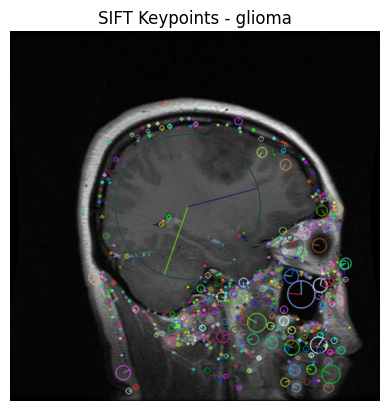

Image: glioma
Number of keypoints detected: 648
Descriptor shape: (648, 128)
--------------------------------------------------


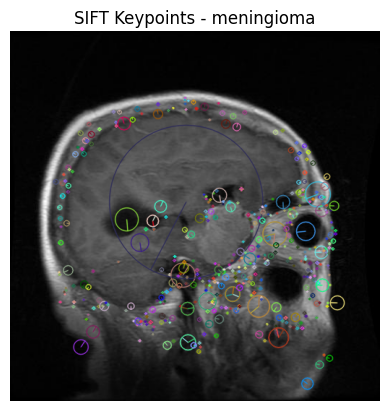

Image: meningioma
Number of keypoints detected: 481
Descriptor shape: (481, 128)
--------------------------------------------------


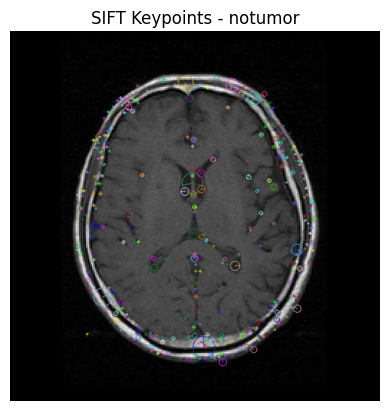

Image: notumor
Number of keypoints detected: 394
Descriptor shape: (394, 128)
--------------------------------------------------


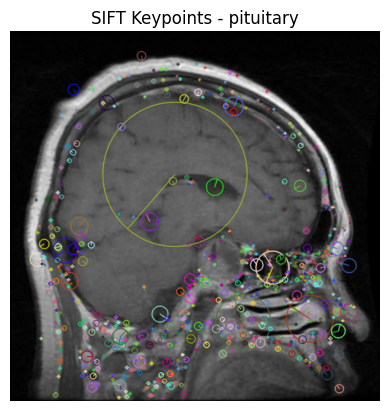

Image: pituitary
Number of keypoints detected: 641
Descriptor shape: (641, 128)
--------------------------------------------------


In [66]:

# ⚠️ Requires: pip install opencv-contrib-python
try:
    sift = cv2.SIFT_create()

    for path, title in zip(paths, titles):
        img = cv2.imread(path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # SIFT Feature Detection
        keypoints, descriptors = sift.detectAndCompute(gray, None)
        sift_img = cv2.drawKeypoints(
            img_rgb, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
        )

        plt.imshow(sift_img)
        plt.title(f"SIFT Keypoints - {title}")
        plt.axis("off")
        plt.show()

        print(f"Image: {title}")
        print("Number of keypoints detected:", len(keypoints))
        if descriptors is not None:
            print("Descriptor shape:", descriptors.shape)
        else:
            print("No descriptors found.")
        print("-" * 50)

except:
    print("SIFT not available. Please install opencv-contrib-python.")


## 10. Feature Extraction – ORB

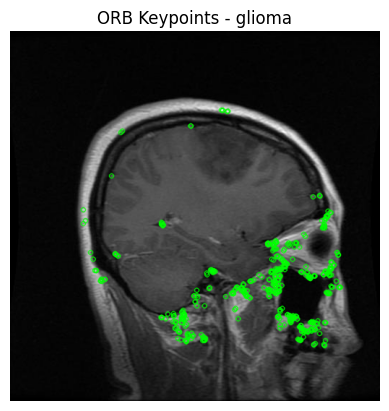

Image: glioma
Number of ORB keypoints detected: 500
Descriptor shape: (500, 32)
--------------------------------------------------


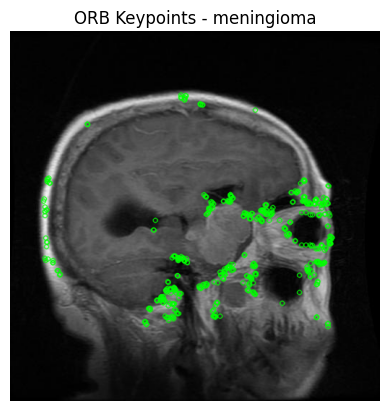

Image: meningioma
Number of ORB keypoints detected: 500
Descriptor shape: (500, 32)
--------------------------------------------------


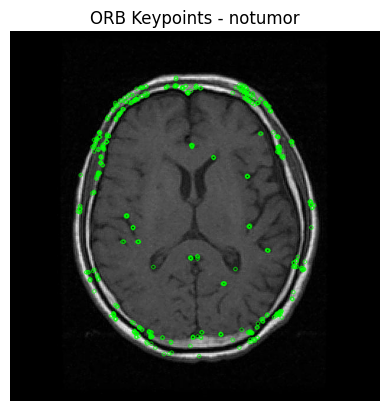

Image: notumor
Number of ORB keypoints detected: 500
Descriptor shape: (500, 32)
--------------------------------------------------


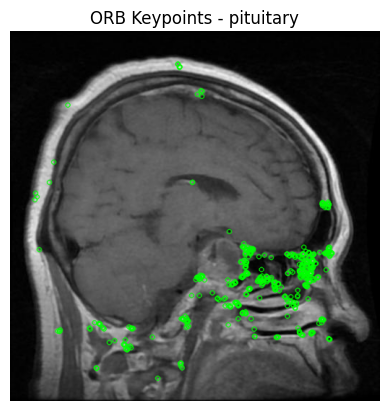

Image: pituitary
Number of ORB keypoints detected: 500
Descriptor shape: (500, 32)
--------------------------------------------------


In [65]:

orb = cv2.ORB_create()

for path, title in zip(paths, titles):
    img = cv2.imread(path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # ORB Feature Detection
    keypoints, descriptors = orb.detectAndCompute(gray, None)
    orb_img = cv2.drawKeypoints(img_rgb, keypoints, None, color=(0, 255, 0), flags=0)

    plt.imshow(orb_img)
    plt.title(f"ORB Keypoints - {title}")
    plt.axis("off")
    plt.show()

    print(f"Image: {title}")
    print("Number of ORB keypoints detected:", len(keypoints))
    if descriptors is not None:
        print("Descriptor shape:", descriptors.shape)
    else:
        print("No descriptors found.")
    print("-" * 50)



## 11. Feature Extraction – HOG (Histogram of Oriented Gradients)

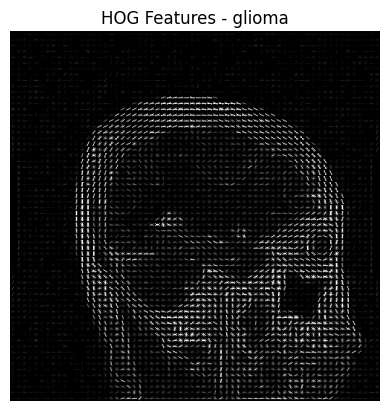

HOG feature vector length for glioma: 142884


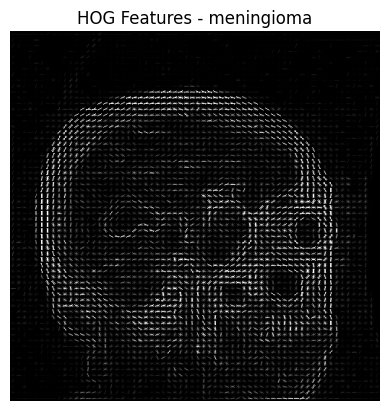

HOG feature vector length for meningioma: 142884


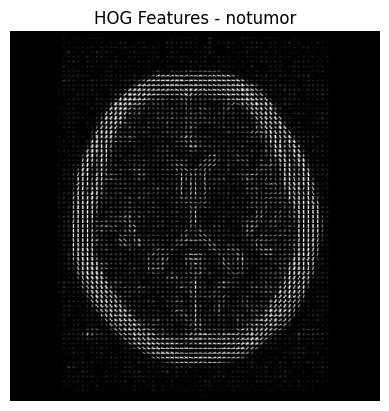

HOG feature vector length for notumor: 213444


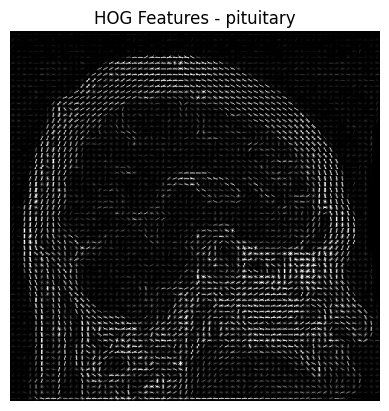

HOG feature vector length for pituitary: 142884


In [63]:

from skimage.feature import hog
from skimage import exposure

for path, title in zip(paths, titles):
    img = cv2.imread(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # HOG Feature Extraction
    hog_features, hog_image = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        visualize=True,
        block_norm='L2-Hys'
    )

    # Rescale untuk visualisasi
    hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))

    plt.imshow(hog_image_rescaled, cmap='gray')
    plt.title(f"HOG Features - {title}")
    plt.axis("off")
    plt.show()

    print(f"HOG feature vector length for {title}: {len(hog_features)}")



In [ ]:
##Texture Analysis GLCM

In [35]:
from skimage.feature import graycomatrix, graycoprops

# Compute GLCM
glcm = graycomatrix(gray,
                    distances=[1],
                    angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                    symmetric=True,
                    normed=True)

# Extract texture features
contrast = graycoprops(glcm, 'contrast')
dissimilarity = graycoprops(glcm, 'dissimilarity')
homogeneity = graycoprops(glcm, 'homogeneity')
energy = graycoprops(glcm, 'energy')
correlation = graycoprops(glcm, 'correlation')
asm = graycoprops(glcm, 'ASM')

print("GLCM Texture Features:")
print("Contrast:", contrast.mean())
print("Dissimilarity:", dissimilarity.mean())
print("Homogeneity:", homogeneity.mean())
print("Energy:", energy.mean())
print("Correlation:", correlation.mean())
print("ASM:", asm.mean())


GLCM Texture Features:
Contrast: 80.31372097896823
Dissimilarity: 4.199673080976068
Homogeneity: 0.41159372332137567
Energy: 0.03913750774609347
Correlation: 0.9343947766111801
ASM: 0.00155788715125194


In [ ]:
##Texture Analysis – Local Binary Patterns (LBP)

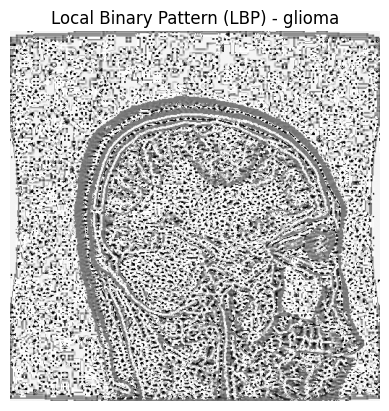

LBP Histogram shape for glioma: (26,)


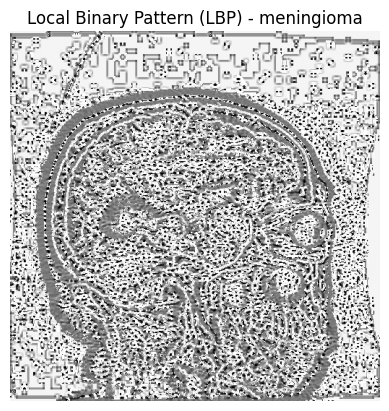

LBP Histogram shape for meningioma: (26,)


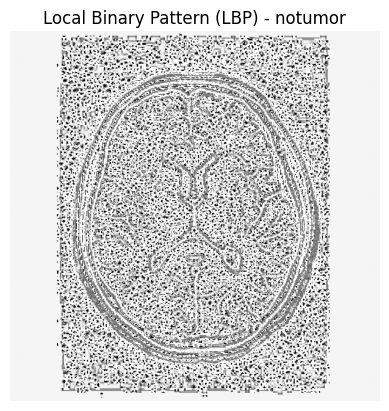

LBP Histogram shape for notumor: (26,)


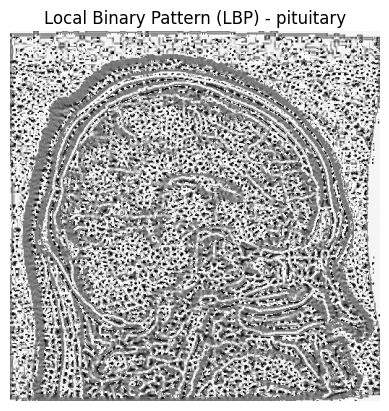

LBP Histogram shape for pituitary: (26,)


In [64]:
from skimage.feature import local_binary_pattern

# Parameter untuk LBP
radius = 3
n_points = 8 * radius

for path, title in zip(paths, titles):
    img = cv2.imread(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Local Binary Pattern
    lbp = local_binary_pattern(gray, n_points, radius, method='uniform')

    plt.imshow(lbp, cmap='gray')
    plt.title(f"Local Binary Pattern (LBP) - {title}")
    plt.axis("off")
    plt.show()

    # Histogram LBP
    n_bins = int(lbp.max() + 1)
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)

    print(f"LBP Histogram shape for {title}: {hist.shape}")

